# 13 | Why does refitting nuisance PCs shift the distributions?

**Learning goals:** separate frequency weighting from distinct temporal coverage, distinguish voxel preprocessing from PCA-loading refits, and compare block subsampling without interpreting a shorter-sample range as a full-run confidence interval.

**Primary FC stability:** notebook 14 recommends 97 distinct frames per session from nonreplacement ten-frame blocks, with complete WM/CSF nuisance refitting. These equal-duration subset ranges are conditional stability summaries, not full-run confidence intervals. The observed full-run points remain unchanged. Notebooks 10/11/13 retain earlier bootstrap, matching and mechanism analyses as sensitivities. See `config/PRIMARY_FC_RESAMPLING.md`. **Current SC policy:** graphs, network means and simulations use each session's 16/20 consensus with mean counts per 10,000 attempted seeds. Primary paired coupling uses the 823-edge intersection with session-specific weights. See `config/PRIMARY_SC.md`. Historical seed-160 diagnostics in notebooks 07/08 remain sensitivity analyses; notebook 09 supplies the reliability evidence. Notebook 10 quantifies joint seed/FC sampling under this policy, including matched designs and support reselection. Notebook 11 extends the full-run branch to paired nuisance refits; notebook 12 integrates all clinical/context fields with network uncertainty. Notebook 13 diagnoses PCA-training shifts and compares nonreplacement blocks at matched distinct counts and 80% retention. The rule is post hoc and does not validate anatomy or a surgical/cognitive effect.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd() if (Path.cwd()/"pyproject.toml").exists() else Path.cwd().parent
os.environ.setdefault("MPLCONFIGDIR", str(root/".cache/matplotlib"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, Markdown, Image
from pat16 import ROOT, DATA, RESULTS, SESSIONS
from pat16.connectivity import labels
from pat16.primary_sc import load_weights
nodes = pd.read_csv(RESULTS/"nodes.csv")
summary = json.loads((RESULTS/"summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9,4), "font.size": 10})


## The result and its scope
The main displacement is associated with relearning the **five-dimensional PCA loading space under repeated-frame weights**. Temporal projection alone is absorbed by existing GLM trend/DCT columns; voxel rescaling alone has little effect. At block 10, loading-only minus fixed-PC coupling contrast shifts by median **+0.02059**, versus **+0.00005** for preprocessing only. These are paired computational interventions, not independent biological mechanisms.

The shift largely disappears when the bootstrap's exact distinct frames each receive unit weight. Independent nonoverlapping block subsets at matched distinct counts give similar global coupling centers. More retained frames reduce sensitivity, but their smaller ranges are conditional on the retained fraction. Neither a displaced bootstrap median nor a negative subsample range replaces the observed primary Δ **−0.04173** or establishes cognitive deterioration. No denoising policy is selected by sign.

,protocol,paired_eligible,requested,summary_available
0,bootstrap_block5,200,200,True
1,unit_coverage_block5,200,200,True
2,block_unique_block5,200,200,True
3,block80_block5,200,200,True
4,bootstrap_block10,200,200,True
5,unit_coverage_block10,200,200,True
6,block_unique_block10,200,200,True
7,block80_block10,200,200,True
8,bootstrap_block20,200,200,True
9,unit_coverage_block20,200,200,True


Maximum bootstrap replay error: 1.8189304229476733e-12


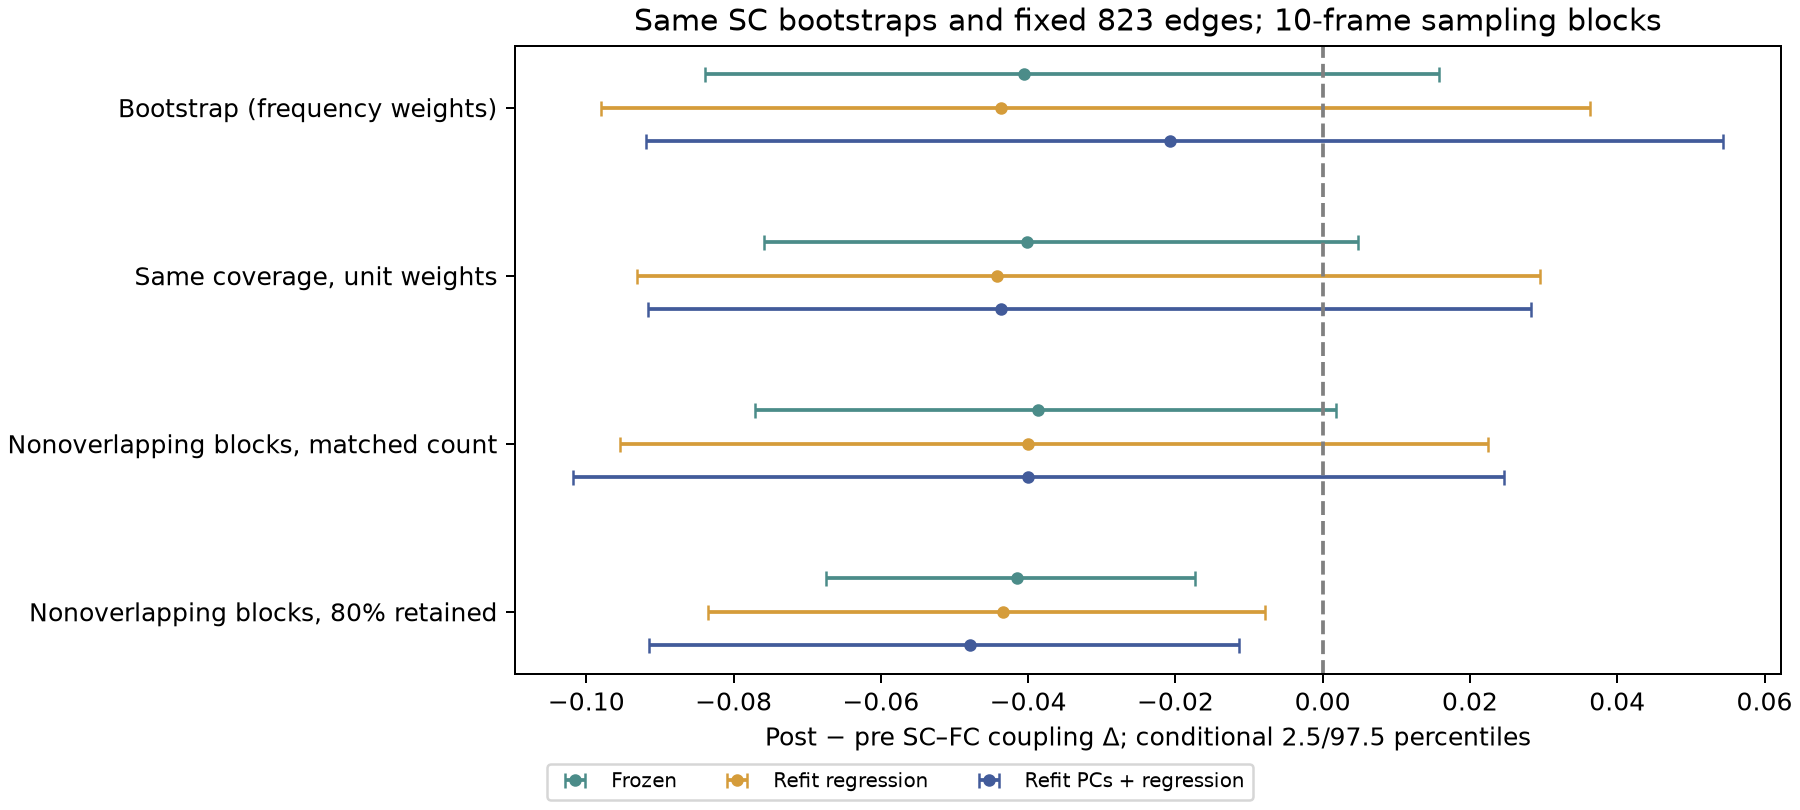

In [2]:
from pat16.pc_sampling import OUT as PCSAM, PROTOCOLS as SP, MODES as SM, DESIGNS as SD
from pat16.pc_sampling_figures import LABELS, MLABELS
sampling_design=json.loads((PCSAM/"design.json").read_text())
ss=pd.read_csv(PCSAM/"summary.csv")
sq=pd.read_csv(PCSAM/"sampling_qc.csv")
fm=pd.read_csv(PCSAM/"fc_metrics.csv")
nr=pd.read_csv(PCSAM/"network_ranges.csv")
fw=np.load(PCSAM/"frame_weights.npy",mmap_mode="r")
display(pd.read_csv(PCSAM/"feasibility.csv"))
print("Maximum bootstrap replay error:",sampling_design["bootstrap_max_absolute_replay_difference"])
display(Image(filename=str(RESULTS/"figures/pc_sampling_ranges.png")))

## Four sampling designs, three nuisance modes
**Bootstrap:** exact saved frequency-weighted draws, 146/150 rows including repeats. **Unit coverage:** same bootstrap draw's distinct frames once; it isolates multiplicities at identical coverage, and is not independent block subsampling. **Blocks, matched:** random circular origin on the original 180 positions; permute nonoverlapping 5/10/20-frame tiles without replacement, omit censored members, trim only the last tile to the bootstrap's exact distinct count. **Blocks, 80%:** same sampler, 116/120 retained frames. Censored gaps remain gaps; all temporal coordinates and derivatives remain original.

Median block-10 distinct counts are 93.5/96 pre/post, with frequency Kish counts 76.1/78.7 for the bootstrap. Kish counts describe concentration of frequency weights, **not independent BOLD sample size**. Matching distinct count does not match FD, temporal coverage, autocorrelation or physiology. Seeds/design/guards were fixed in `config/PC_SAMPLING.md` before computing contrasts. All 200 paired draws pass the existing safeguards in every design/block. Strict full-run bootstrap failure remains unchanged; earlier 68-frame duration/FD/run-half matching is in notebooks 07/10.

All modes use identical draws: frozen residuals; frozen PCs with regression refitted; or complete tissue preprocessing, PCA and regression refits. The same 500 whole-run SC bootstraps are crossed with 200 FC draws on the fixed 823 edges. The 100,000 cells are dependent. New support-reselected full-refit sensitivities are available at block 10.

,protocol,mode,FC_draws,median,q025,q975,FC_share
14,bootstrap_block10,full_refit,200,-0.020689,-0.091888,0.054422,0.991119
17,unit_coverage_block10,full_refit,200,-0.043662,-0.091625,0.028341,0.987763
21,block_unique_block10,full_refit,200,-0.040013,-0.101862,0.024614,0.987845
25,block80_block10,full_refit,200,-0.047840,-0.091546,-0.011393,0.970446


rows  unique  frequency_Kish_count   mean_fd  \
design        session                                                  
block80       postop   120.0   120.0            120.000000  0.252507   
              preop    116.0   116.0            116.000000  0.286693   
block_unique  postop    96.0    96.0             96.000000  0.251342   
              preop     93.5    93.5             93.500000  0.286718   
bootstrap     postop   150.0    96.0             78.671329  0.250509   
              preop    146.0    93.5             76.128571  0.288850   
unit_coverage postop    96.0    96.0             96.000000  0.252294   
              preop     93.5    93.5             93.500000  0.288791   

                       first_half_unique  
design        session                     
block80       postop                64.0  
              preop                 61.0  
block_unique  postop                52.0  
              preop                 49.0  
bootstrap     postop                52.0  
              preop                 49.0  
unit_coverage postop                52.0  
              preop                 49.0

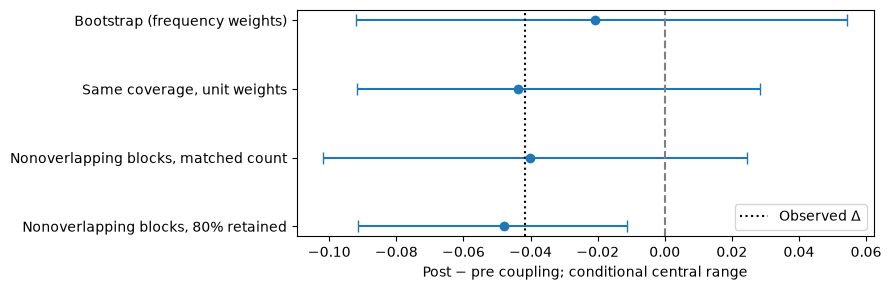

interactive(children=(Dropdown(description='block', index=1, options=(5, 10, 20), value=10), Dropdown(descript…

<function __main__.sampling_comparison(block=10, mode='full_refit')>

In [3]:
def sampling_comparison(block=10,mode="full_refit"):
    v=ss[(ss.protocol.str.endswith("_block"+str(block)))&(ss.support=="fixed")&(ss["mode"]==mode)].copy()
    display(v[["protocol","mode","FC_draws","median","q025","q975","FC_share"]])
    display(sq[sq.block==block].groupby(["design","session"])[["rows","unique","frequency_Kish_count","mean_fd","first_half_unique"]].median())
    fig,ax=plt.subplots(figsize=(9,3));y=np.arange(len(v))
    ax.errorbar(v["median"],y,xerr=np.vstack([v["median"]-v.q025,v.q975-v["median"]]),fmt="o",capsize=4)
    ax.set_yticks(y,[LABELS[p.rsplit("_block",1)[0]] for p in v.protocol]);ax.invert_yaxis()
    ax.axvline(0,color="gray",ls="--");ax.axvline(-.0417277272,color="black",ls=":",label="Observed Δ")
    ax.set_xlabel("Post − pre coupling; conditional central range");ax.legend();plt.tight_layout();plt.show();plt.close(fig)
widgets.interact(sampling_comparison,block=widgets.Dropdown(options=[5,10,20],value=10),mode=widgets.Dropdown(options=list(SM),value="full_refit"))

## Inspect a saved draw and the exact multiplicity control
On the same original positions, bootstrap weights can exceed one. Unit coverage equals their indicator exactly. Matched-count block subsets have the same number of distinct frames but different positions. Each tile is used once; censoring and a trimmed last tile mean they are not contiguous short scans. Compare session-specific mean FD and thirds before interpreting coverage.

,protocol,design,block,session,draw,rows,unique,repeated,max_multiplicity,frequency_Kish_count,mean_fd,first_half_unique,adjacent_unique,span_minutes,unique_minutes,third1,third2,third3
1600,bootstrap_block10,bootstrap,10,preop,0,146,104,42,3,85.951613,0.294622,43,91,6.96,4.16,37,30,37
1800,bootstrap_block10,bootstrap,10,postop,0,150,99,51,3,83.955224,0.264521,63,85,6.92,3.96,40,37,22
2000,unit_coverage_block10,unit_coverage,10,preop,0,104,104,0,1,104.000000,0.294443,43,91,6.96,4.16,37,30,37
2200,unit_coverage_block10,unit_coverage,10,postop,0,99,99,0,1,99.000000,0.264508,63,85,6.92,3.96,40,37,22
2400,block_unique_block10,block_unique,10,preop,0,104,104,0,1,104.000000,0.282309,57,97,7.00,4.16,34,35,35
2600,block_unique_block10,block_unique,10,postop,0,99,99,0,1,99.000000,0.255394,54,89,6.52,3.96,45,25,29
2800,block80_block10,block80,10,preop,0,116,116,0,1,116.000000,0.290795,66,109,5.96,4.64,44,40,32
3000,block80_block10,block80,10,postop,0,120,120,0,1,120.000000,0.250490,63,110,6.92,4.80,36,51,33


,protocol,session,unique,design_rank,distinct_rows_minus_rank,adjusted_PC_cos2_min,gap5_relative,cortical_mean_PC_removed,mean_fc_r
4802,bootstrap_block10,preop,104,39.0,65.0,0.081448,0.012133,0.758629,0.169032
5402,bootstrap_block10,postop,99,39.0,60.0,0.049620,0.117201,0.737587,0.098597
6002,unit_coverage_block10,preop,104,39.0,65.0,0.153504,0.060855,0.878225,0.083238
6602,unit_coverage_block10,postop,99,39.0,60.0,0.878801,0.050052,0.837593,0.062229
7202,block_unique_block10,preop,104,39.0,65.0,0.421168,0.043182,0.904630,0.096290
7802,block_unique_block10,postop,99,39.0,60.0,0.804080,0.060089,0.912941,0.044306
8402,block80_block10,preop,116,39.0,77.0,0.081857,0.048213,0.800885,0.133714
9002,block80_block10,postop,120,39.0,81.0,0.283260,0.050697,0.885074,0.052568


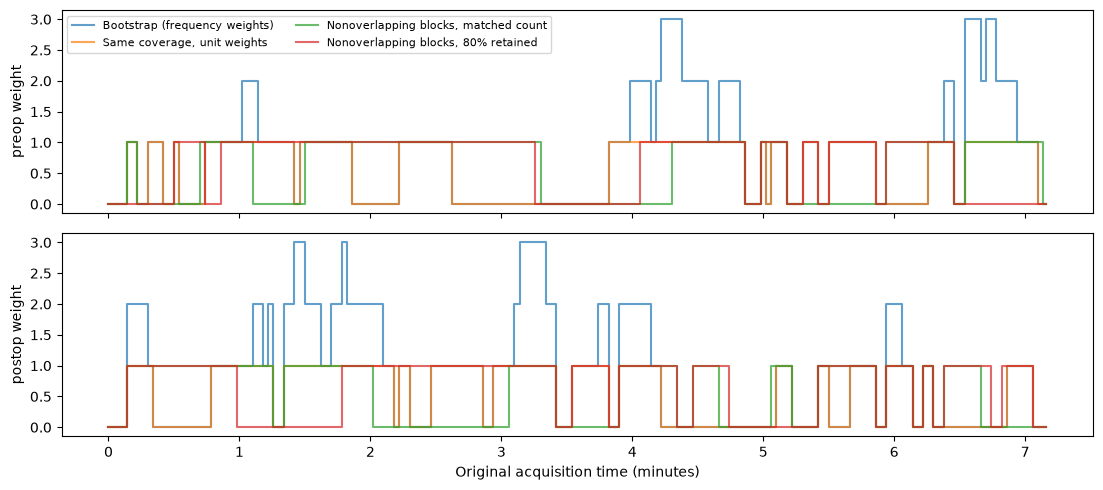

interactive(children=(Dropdown(description='block', index=1, options=(5, 10, 20), value=10), IntSlider(value=0…

<function __main__.inspect_sampling(block=10, draw=0)>

In [4]:
def inspect_sampling(block=10,draw=0):
    protocols=[d+"_block"+str(block) for d in SD]
    display(sq[sq.protocol.isin(protocols)&(sq.draw==draw)])
    display(fm[fm.protocol.isin(protocols)&(fm.draw==draw)&(fm["mode"]=="full_refit")][["protocol","session","unique","design_rank","distinct_rows_minus_rank","adjusted_PC_cos2_min","gap5_relative","cortical_mean_PC_removed","mean_fc_r"]])
    fig,axs=plt.subplots(2,1,figsize=(11,5),sharex=True)
    for t,ax in enumerate(axs):
        for design in SD:
            p=list(SP).index(design+"_block"+str(block));ax.step(np.arange(180)*2.4/60,fw[p,t,draw],where="mid",alpha=.7,label=LABELS[design])
        ax.set_ylabel(SESSIONS[t]+" weight")
    axs[0].legend(ncol=2,fontsize=8);axs[-1].set_xlabel("Original acquisition time (minutes)");plt.tight_layout();plt.show();plt.close(fig)
    a=fw[list(SP).index("bootstrap_block"+str(block)),:,draw]
    b=fw[list(SP).index("unit_coverage_block"+str(block)),:,draw]
    assert np.array_equal(a>0,b)
widgets.interact(inspect_sampling,block=widgets.Dropdown(options=[5,10,20],value=10),draw=widgets.IntSlider(min=0,max=199,value=0,continuous_update=False))

## Factorial training controls explain the shift
Refit all regression coefficients in every condition, on exactly the same weighted block-10 rows. Change tissue preprocessing only, PCA loadings only, or both. A separate temporal-only control freezes voxel scales/loadings. If background basis T is already in the final GLM, replacing tissue Z by Z−TA changes fixed-loading PC scores only within span(T), hence the fitted residuals are identical. PC signs and rotations within an unchanged span cannot explain a shift.

After projecting out the **same weighted motion/trend/DCT background**, the median minimum PC-span cosine² is 0.033/0.082 with bootstrap refits, versus 0.278/0.618 for unit coverage and 0.391/0.820 at 80% retention. This is not the earlier raw-PC-span metric. Baseline relative eigenvalue gaps (λ5−λ6)/λ5 are 0.015 pre-op and 0.046 post-op; a small gap is compatible with a sensitive five-PC boundary, but is not proof of a single PC swap. A larger gap after refitting does not certify stability relative to baseline.

PCA maximizes variance in the selected WM/CSF voxel data. More captured tissue variance does not guarantee removing the same cortical shared signal. Under bootstrap refitting, median cortical-mean variance removed relative to the same draw's background GLM drops from 0.899 to 0.600 pre-op and 0.902 to 0.806 post-op. This leaves more common cortical signal and raises mean FC, especially pre-op. Its neural/noise composition is unknown. Coupling ranks and network FC averages are different statistics and can move differently.

,mode,q025,median,q975,sd,positive_fraction,SC_variance,FC_variance,interaction_variance,total_variance,SC_share,FC_share,interaction_share
0,coefficients,-0.097952,-0.043640,0.036360,0.035366,0.11750,0.000009,0.001238,0.000004,0.001251,0.007357,0.989519,0.003124
1,temporal_only,-0.097952,-0.043640,0.036360,0.035366,0.11750,0.000009,0.001238,0.000004,0.001251,0.007357,0.989519,0.003124
2,preprocessing_only,-0.097915,-0.043663,0.036193,0.035268,0.11665,0.000009,0.001231,0.000004,0.001244,0.007382,0.989478,0.003141
3,pca_only,-0.099566,-0.022752,0.056157,0.038745,0.29187,0.000009,0.001488,0.000005,0.001501,0.005835,0.991039,0.003125
4,full_refit,-0.091888,-0.020689,0.054422,0.038769,0.32132,0.000009,0.001490,0.000005,0.001503,0.005798,0.991119,0.003083


,contrast,q025,median,q975,sd,positive_fraction
0,temporal_minus_coefficients,0.000000,0.000000,0.000000,0.000000,0.00000
1,preprocessing_minus_coefficients,-0.001795,0.000054,0.001644,0.000924,0.51847
2,full_minus_preprocessing,-0.031906,0.023318,0.073054,0.025309,0.82380
3,pca_minus_coefficients,-0.031467,0.020589,0.068713,0.025539,0.79058
4,full_minus_pca,-0.018300,0.001407,0.022535,0.009361,0.57307
5,full_minus_coefficients,-0.031034,0.023495,0.072460,0.025038,0.82556


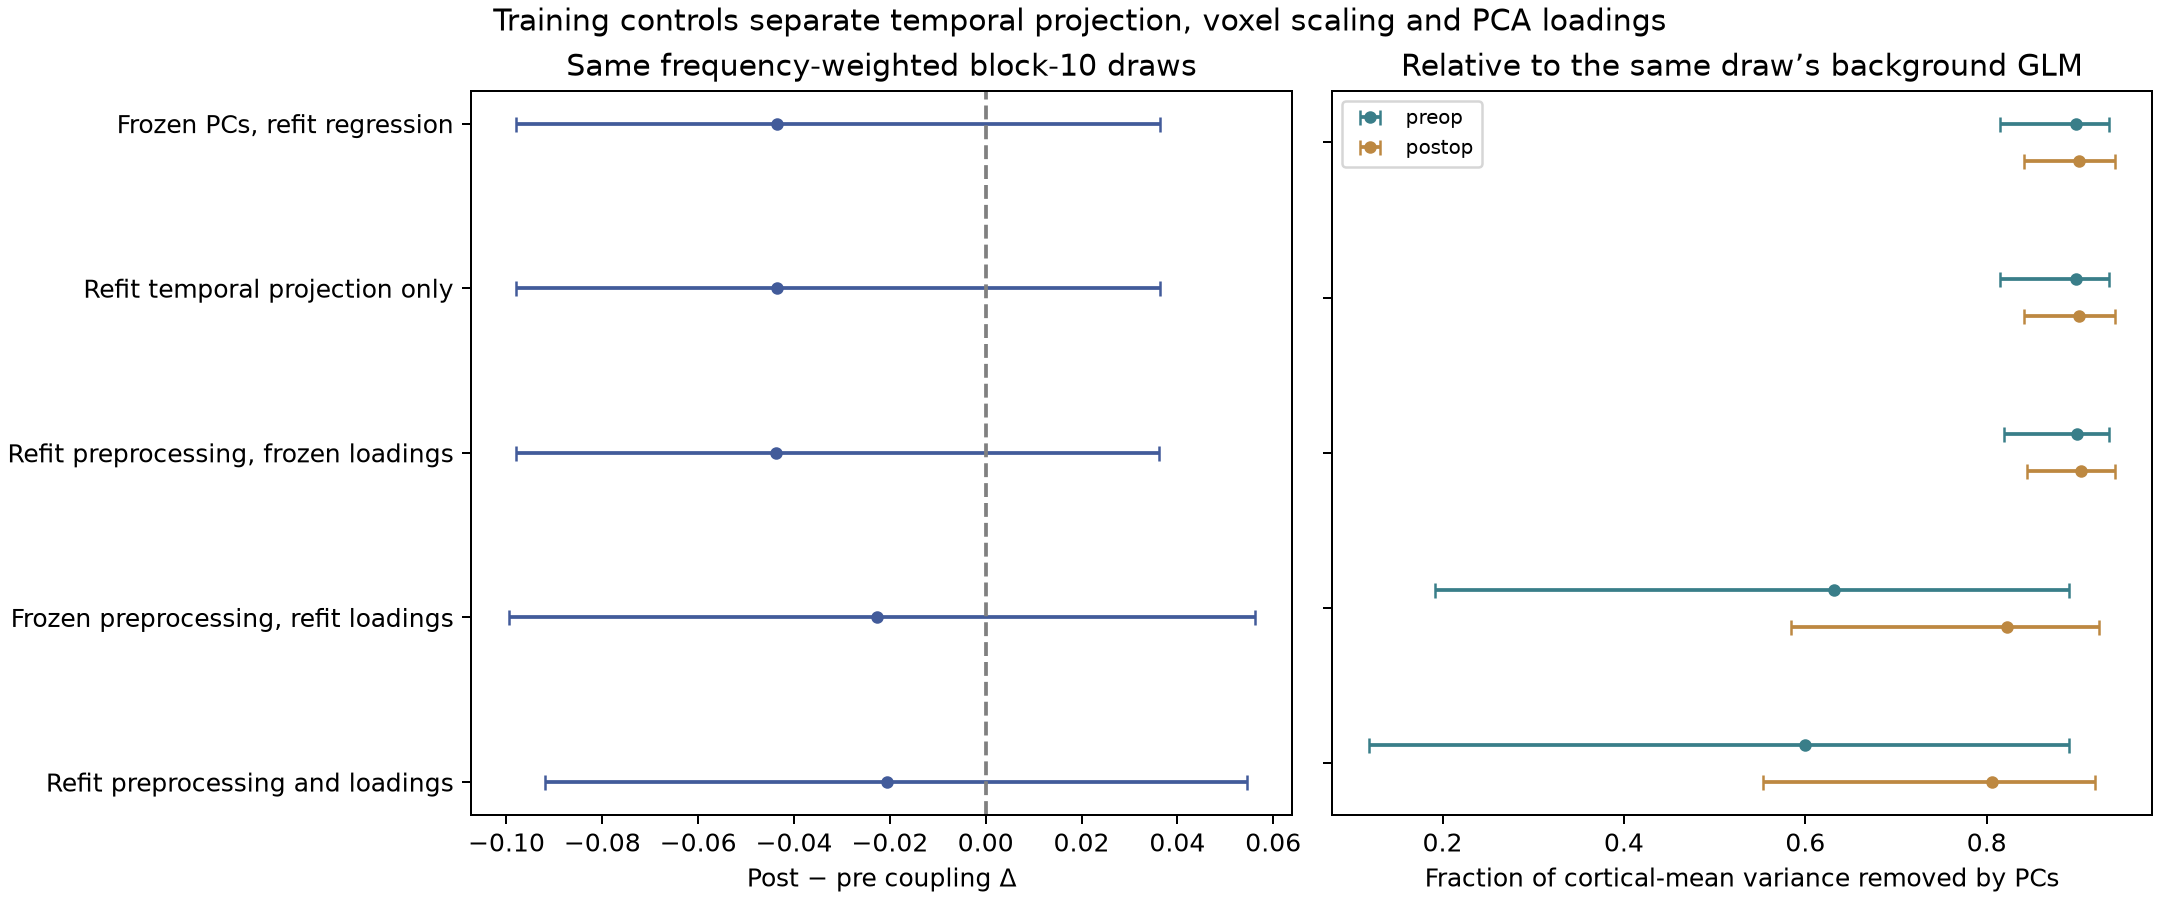

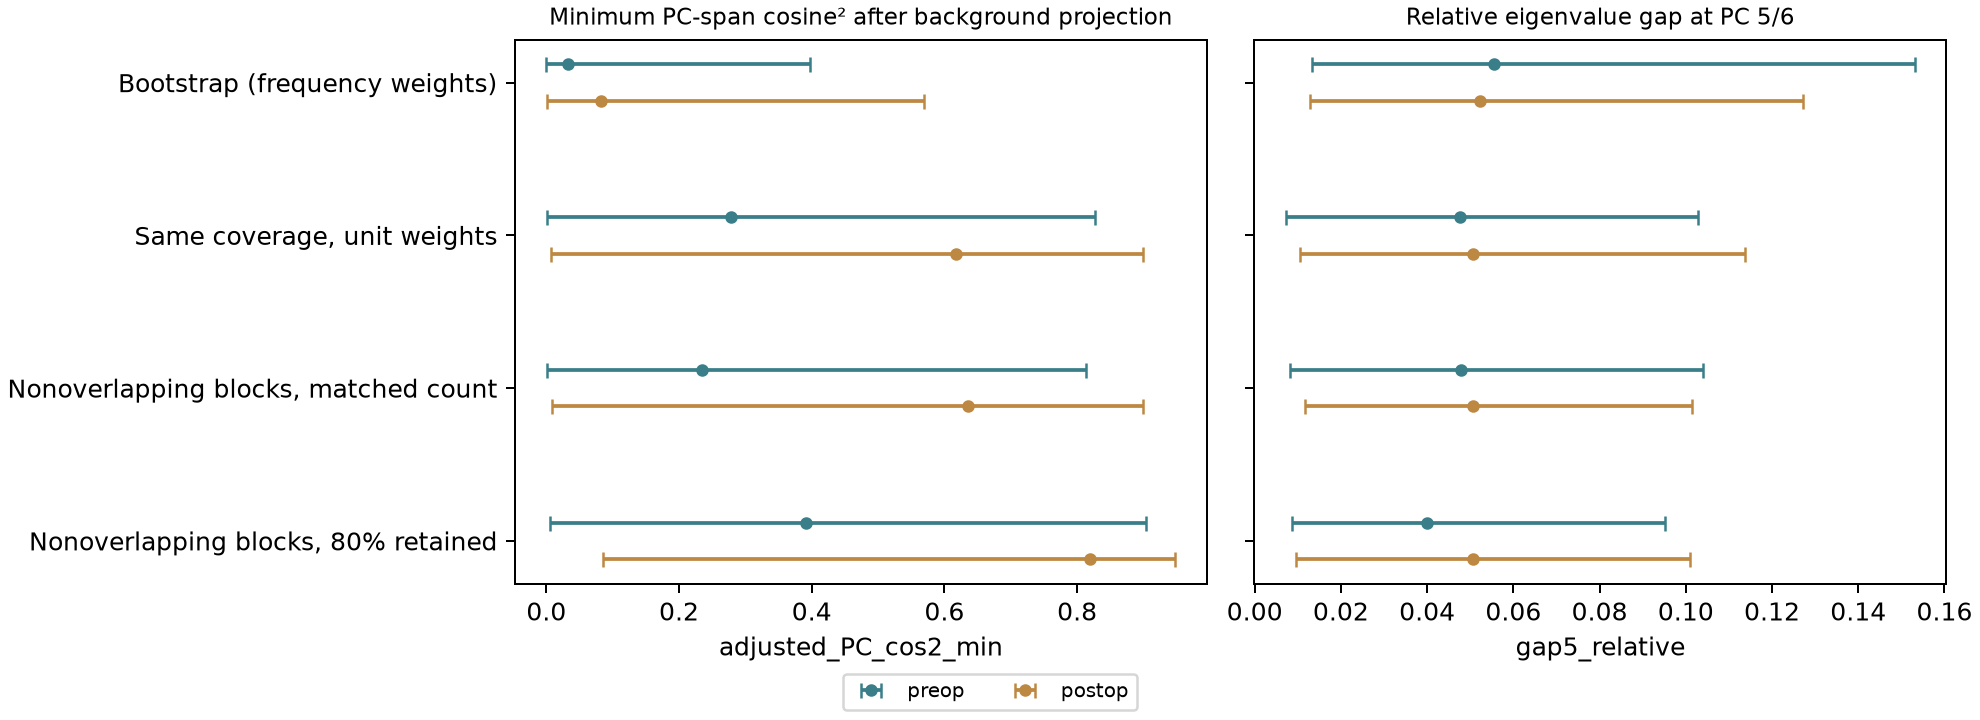

adjusted_PC_cos2_min  PCA5_fraction  \
mode               session                                        
coefficients       postop               1.000000       0.174112   
                   preop                1.000000       0.150549   
full_refit         postop               0.081646       0.209863   
                   preop                0.033215       0.192233   
pca_only           postop               0.084304       0.209199   
                   preop                0.034218       0.193477   
preprocessing_only postop               0.999533       0.174112   
                   preop                0.999186       0.150549   
temporal_only      postop               1.000000       0.174112   
                   preop                1.000000       0.150549   

                            gap5_relative  cortical_mean_PC_removed  mean_fc_r  
mode               session                                                      
coefficients       postop        0.046219                  0.902208   0.047122  
                   preop         0.015336                  0.898798   0.079180  
full_refit         postop        0.052369                  0.805828   0.086981  
                   preop         0.055597                  0.599632   0.230962  
pca_only           postop        0.053876                  0.822338   0.081521  
                   preop         0.059029                  0.631735   0.213724  
preprocessing_only postop        0.046219                  0.904361   0.046627  
                   preop         0.015336                  0.899856   0.077508  
temporal_only      postop        0.046219                  0.902208   0.047122  
                   preop         0.015336                  0.898798   0.079180

Temporal-only maximum |FC difference|: 3.193695308212341e-13


In [5]:
display(pd.read_csv(PCSAM/"mechanism_summary.csv"))
display(pd.read_csv(PCSAM/"mechanism_shifts.csv"))
display(Image(filename=str(RESULTS/"figures/pc_sampling_mechanism.png")))
display(Image(filename=str(RESULTS/"figures/pc_sampling_stability.png")))
mm=pd.read_csv(PCSAM/"mechanism_metrics.csv")
display(mm.groupby(["mode","session"])[["adjusted_PC_cos2_min","PCA5_fraction","gap5_relative","cortical_mean_PC_removed","mean_fc_r"]].median())
mechanism_fc=np.load(PCSAM/"mechanism_fc.npy",mmap_mode="r")
print("Temporal-only maximum |FC difference|:",np.max(np.abs(mechanism_fc[0]-mechanism_fc[1])))

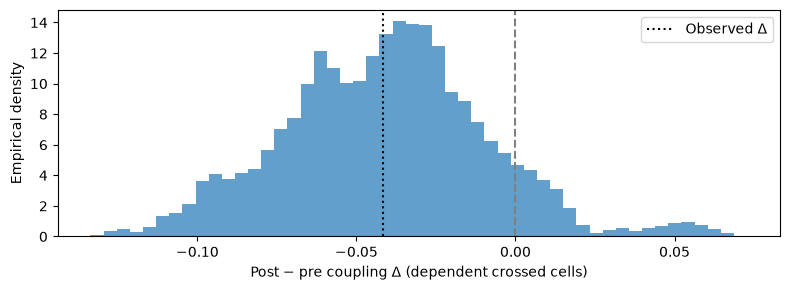

interactive(children=(Dropdown(description='design', index=2, options=('bootstrap', 'unit_coverage', 'block_un…

<function __main__.crossed_distribution(design='block_unique', mode='full_refit', block=10, support='fixed')>

In [6]:
def crossed_distribution(design="block_unique",mode="full_refit",block=10,support="fixed"):
    name=f"{design}_block{block}_{support}_{mode}.npz";path=PCSAM/name
    if not path.exists():
        display(Markdown("Support reselection here is saved only for the three new block-10 full-refit designs; the prior bootstrap reselection is in notebook 11."));return
    z=np.load(path);fig,ax=plt.subplots(figsize=(8,3))
    ax.hist(z["delta"].ravel(),bins=50,density=True,alpha=.7)
    ax.axvline(-.0417277272,color="black",ls=":",label="Observed Δ");ax.axvline(0,color="gray",ls="--")
    ax.set_xlabel("Post − pre coupling Δ (dependent crossed cells)");ax.set_ylabel("Empirical density");ax.legend();plt.tight_layout();plt.show();plt.close(fig)
widgets.interact(crossed_distribution,design=widgets.Dropdown(options=list(SD),value="block_unique"),mode=widgets.Dropdown(options=list(SM),value="full_refit"),block=widgets.Dropdown(options=[5,10,20],value=10),support=widgets.Dropdown(options=["fixed","reselected"]))

## Clinical interpretation and retained-fraction caveat
Visual FC's observed change remains −0.0045 Fisher z. Its full-refit median is −0.1993 under the bootstrap, −0.0458 at unit coverage, −0.0355 with matched-count blocks and −0.0143 with 80% retention. This displacement does not diagnose a visual deficit. The sensorimotor matched-count block range crosses zero, unlike the original full-refit bootstrap range. Dorsal-attention/default ranges remain negative in the new block-10 subsets, but these are exploratory, dependent summaries and do not localize clinical changes.

MOT slowing, RTI speeding, SSP span 6→7 and mixed SOC/RVP remain a mixed measured profile. Worry/loneliness, anxiety, emotion regulation and employment remain distinct unlocalized contextual observations. All 47 source fields, missingness and appendix dictionaries are preserved; no composite or clinical error bars are invented. Notebook [12](12_connectivity_cognition_context.ipynb) now compares the new network ranges beside each clinical field's candidate networks.

The 80% full-refit coupling range is [−0.0915,−0.0114] at block 10, but at 100% without replacement there is **no FC sampling spread** and the observed FC is recovered exactly (SC seed variability remains). Thus sampling-fraction-dependent ranges must not be substituted for calibrated full-run uncertainty or selected for a favorable sign. We retain full refitting for the estimator's sampling analysis, report the bootstrap and nonreplacement controls together, and do not claim one estimates population bias or neural truth.

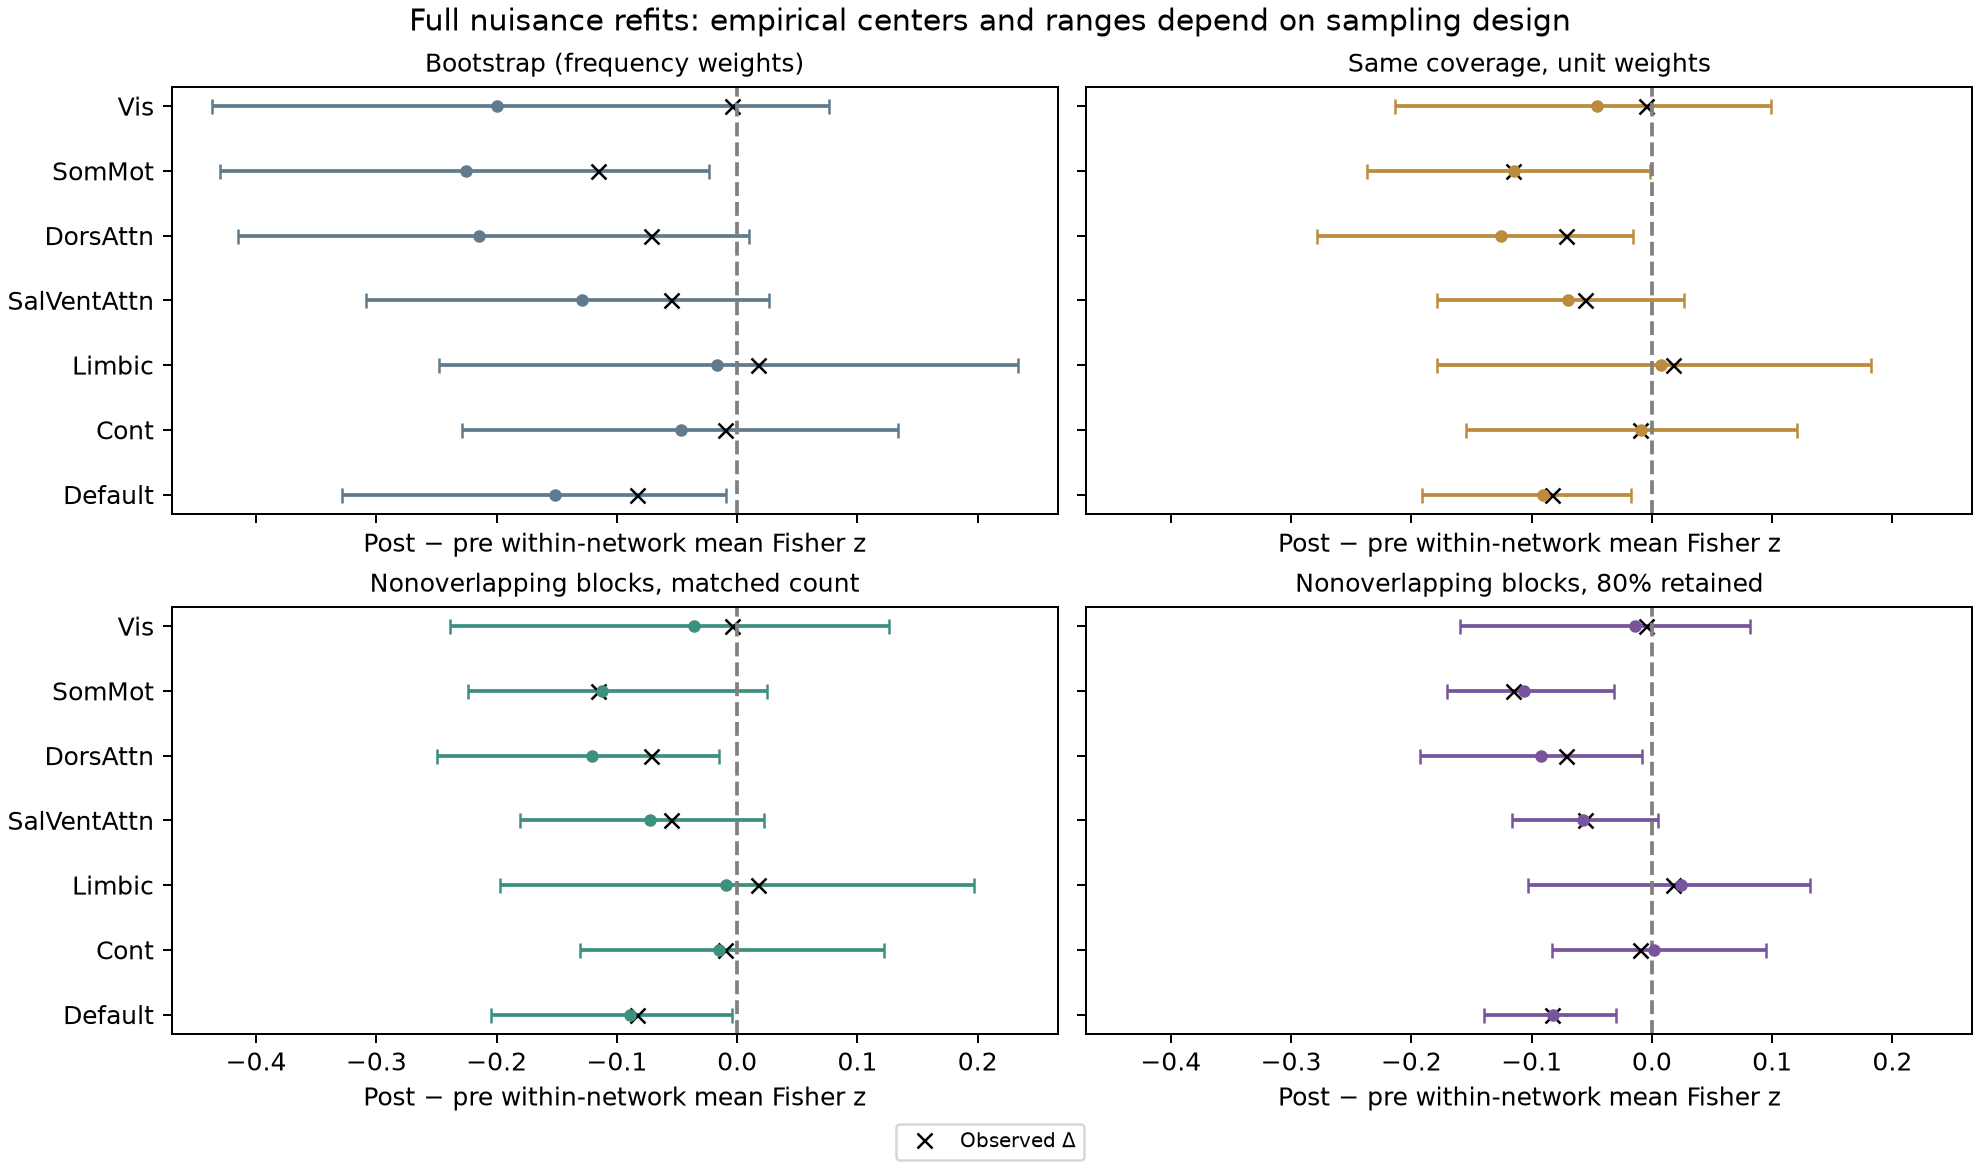

,protocol,network,observed_delta,median,q025,q975
98,bootstrap_block10,Vis,-0.004493,-0.199323,-0.436707,0.076115
99,bootstrap_block10,SomMot,-0.115760,-0.225193,-0.429788,-0.023769
100,bootstrap_block10,DorsAttn,-0.071292,-0.214471,-0.415071,0.009675
101,bootstrap_block10,SalVentAttn,-0.055324,-0.128612,-0.308414,0.026341
102,bootstrap_block10,Limbic,0.017272,-0.016649,-0.247837,0.233084
103,bootstrap_block10,Cont,-0.010065,-0.046972,-0.228363,0.133392
104,bootstrap_block10,Default,-0.083192,-0.151400,-0.328695,-0.009506
119,unit_coverage_block10,Vis,-0.004493,-0.045776,-0.213542,0.098724
120,unit_coverage_block10,SomMot,-0.115760,-0.114787,-0.237140,-0.001568
121,unit_coverage_block10,DorsAttn,-0.071292,-0.125610,-0.278125,-0.015987


Unchanged clinical fields: 47 ; CANTAB: 28


,protocol,mode,support,FC_draws,SC_draws,half,q025,median,q975,sd,positive_fraction
8,bootstrap_block5,full_refit,fixed,200,500,SC_first,-0.073188,-0.014588,0.053081,0.032580,0.32444
9,bootstrap_block5,full_refit,fixed,200,500,SC_second,-0.073413,-0.014742,0.052340,0.032596,0.32342
10,bootstrap_block5,full_refit,fixed,200,500,FC_first,-0.072325,-0.008250,0.061365,0.035213,0.41220
11,bootstrap_block5,full_refit,fixed,200,500,FC_second,-0.074186,-0.018848,0.035807,0.028686,0.23566
20,unit_coverage_block5,full_refit,fixed,200,500,SC_first,-0.090386,-0.037486,0.025984,0.029595,0.10038
21,unit_coverage_block5,full_refit,fixed,200,500,SC_second,-0.090658,-0.037617,0.025507,0.029600,0.09942
22,unit_coverage_block5,full_refit,fixed,200,500,FC_first,-0.090323,-0.036105,0.036562,0.032397,0.12888
23,unit_coverage_block5,full_refit,fixed,200,500,FC_second,-0.090683,-0.039173,0.018330,0.026121,0.07092
32,block_unique_block5,full_refit,fixed,200,500,SC_first,-0.100138,-0.040110,0.020566,0.030050,0.10436
33,block_unique_block5,full_refit,fixed,200,500,SC_second,-0.100292,-0.040205,0.020579,0.030068,0.10338


In [7]:
display(Image(filename=str(RESULTS/"figures/pc_sampling_networks.png")))
display(nr[(nr.protocol.str.endswith("block10"))&(nr["mode"]=="full_refit")][["protocol","network","observed_delta","median","q025","q975"]])
links=pd.read_csv(PCSAM/"clinical_field_links.csv")
print("Unchanged clinical fields:",len(links),"; CANTAB:",(links.group=="CANTAB").sum())
display(pd.read_csv(PCSAM/"monte_carlo_halves.csv").query("mode == 'full_refit' and support == 'fixed'"))

## Reproduce and interrogate
`uv run python scripts/investigate_pc_sampling.py` verifies cached inputs or recomputes all designs, factorial controls and figures. `results/pc_sampling/design.json` fingerprints source, saved draws and outputs; `results/before_pc_sampling` preserves the preceding delivery.

**Exercises:** change block size and retained design; compare coefficient-only versus full refits at fixed coverage; explain temporal-only invariance; distinguish a small boundary eigengap from measured subspace overlap; explain why removing duplicates changes the estimator rather than repairs a conventional bootstrap; compare global coupling versus visual/sensorimotor FC; explain why the 80% negative range supplies no reliable-change test for MOT or QoL. Test the 100% sampler/fit identity with `tests/test_pc_sampling.py`. Independent repeat runs and physiological measurements are needed to resolve neural versus nuisance contributions.